# Puntualidad de la aviación comercial en EE. UU.

**Cuadernillo 01 — Fases 1 y 2 de CRISP-DM: negocio, datos y calidad**

Curso: Ciencia de Datos · Autor/a: *(completar)* · Fecha: 16/11/2026
Datos: 11 730 351 vuelos domésticos (2025-01-01 → 2026-08-31), 14 aerolíneas, 361 aeropuertos.

## 1. Comprensión del negocio

**Pregunta:** ¿qué factores explican que un vuelo llegue con 15 minutos o más de retraso y con qué fiabilidad se puede anticipar antes del despegue?

**Objetivo:** predecir `arr_del15` usando sólo información disponible antes de la salida.

| Criterio de éxito | Umbral |
|---|---|
| AUC-ROC | ≥ 0,75 |
| F1 (clase retrasada) | ≥ 0,55 |
| Recall | ≥ 0,50 |
| Filas válidas tras limpieza | ≥ 97 % |

**Alcance:** vuelos domésticos de EE. UU. **Riesgo principal:** fuga de información — `dep_delay`, `taxi_out`, `arr_time` y las causas son posteriores al despegue.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq
from scipy import stats

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
SEMILLA = 42
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, FIG, TAB = RAIZ/"data"/"raw", RAIZ/"reports"/"figures", RAIZ/"reports"/"tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA, ROJO, VERDE, GRIS = "#1f4e79", "#ed7d31", "#c00000", "#548235", "#7f7f7f"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.titlesize": 11,
                     "axes.titleweight": "bold", "axes.grid": True, "grid.alpha": .3,
                     "grid.linestyle": "--", "axes.spines.top": False,
                     "axes.spines.right": False, "legend.frameon": False})

def save(fig, nombre):
    fig.tight_layout(); fig.savefig(FIG/nombre, bbox_inches="tight", dpi=150, facecolor="white")

miles = plt.FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", "."))
print("pandas", pd.__version__, "| raíz:", RAIZ.name)

pandas 3.1.1 | raíz: Proyecto


## 2. Comprensión de los datos

### 2.1 Fuentes

Cinco archivos: una tabla de hechos (Parquet) y cuatro auxiliares que sirven de catálogo y de **control cruzado**.

In [2]:
filas = []
for f in sorted(RAW.iterdir()):
    if f.suffix == ".parquet":
        meta = pq.ParquetFile(f).metadata
        n, c = meta.num_rows, meta.num_columns
    else:
        n, c = sum(1 for _ in open(f, "rb")) - 1, pd.read_csv(f, nrows=0).shape[1]
    filas.append({"archivo": f.name, "filas": n, "columnas": c,
                  "MB": round(f.stat().st_size / 1024**2, 1)})
pd.DataFrame(filas)

,archivo,filas,columnas,MB
0,airlines.csv,14,7,0.00
1,airports.csv,361,11,0.00
2,daily_airport_stats.csv,202872,13,10.60
3,flights.parquet,11730351,40,299.40
4,flights_sample.csv,500000,40,85.40


### 2.2 Carga

Se leen sólo las 33 columnas necesarias (proyección en Parquet) y se construye una **muestra estratificada por mes** (1 de cada 15 vuelos) para los gráficos de nivel de fila.

In [3]:
COLS = ["flight_date", "month", "day_of_week", "airline", "tail_number", "flight_number",
        "origin", "origin_state", "dest", "dest_state", "sched_dep_time", "dep_time",
        "dep_delay", "dep_del15", "taxi_out", "sched_arr_time", "arr_time", "taxi_in",
        "arr_delay", "arr_del15", "cancelled", "cancellation_code", "cancellation_reason",
        "diverted", "sched_elapsed_time", "actual_elapsed_time", "air_time", "distance",
        "carrier_delay", "weather_delay", "nas_delay", "security_delay", "late_aircraft_delay"]

df = pq.read_table(RAW/"flights.parquet", columns=COLS).to_pandas()
df["fecha"] = pd.to_datetime(df["flight_date"])
df["hora"] = (df["sched_dep_time"] // 100).clip(0, 23).astype("int8")
muestra = (df.groupby("month", group_keys=False, observed=True)
             .sample(frac=1/15, random_state=SEMILLA).reset_index(drop=True))

print(f"completa: {df.shape[0]:,} × {df.shape[1]} | muestra: {len(muestra):,} "
      f"| RAM: {df.memory_usage(deep=True).sum()/1024**2:,.0f} MB")
print(f"periodo: {df.fecha.min():%Y-%m-%d} → {df.fecha.max():%Y-%m-%d} "
      f"({df.fecha.nunique()} días) | rutas: {df.groupby(['origin','dest'], observed=True).ngroups:,}")

completa: 11,730,351 × 35 | muestra: 782,025 | RAM: 1,299 MB


periodo: 2025-01-01 → 2026-08-31 (608 días) | rutas: 7,344


### 2.3 Diccionario y estructura

Tipos, nulos y cardinalidad en una sola tabla. **Los nulos no son aleatorios**: dependen del estado del vuelo (se verifican en §3.2).

In [4]:
DESC = {"flight_date": "fecha local", "month": "mes (1-12)", "day_of_week": "1 = lunes … 7 = domingo",
        "airline": "aerolínea operadora", "tail_number": "matrícula", "flight_number": "nº de vuelo",
        "origin": "aeropuerto origen (IATA)", "dest": "aeropuerto destino",
        "sched_dep_time": "salida programada HHMM", "dep_time": "salida real",
        "dep_delay": "retraso de salida (min)", "arr_delay": "retraso de llegada (min)",
        "arr_del15": "1 si retraso ≥ 15 min (objetivo)", "cancelled": "cancelado",
        "diverted": "desviado", "air_time": "tiempo en el aire (min)", "distance": "millas",
        "sched_elapsed_time": "duración programada (min)", "taxi_out": "rodaje en origen (min)",
        "cancellation_reason": "causa de cancelación", "carrier_delay": "min atribuidos a la aerolínea"}

perfil = pd.DataFrame({"tipo": df.dtypes.astype(str), "nulos": df.isna().sum(),
                       "nulos_%": (df.isna().mean()*100).round(2), "unicos": df.nunique()})
perfil["descripcion"] = pd.Series(DESC).reindex(perfil.index).fillna("—")
perfil.to_csv(TAB/"01_diccionario.csv", sep=";", decimal=",", encoding="utf-8-sig")
perfil

,tipo,nulos,nulos_%,unicos,descripcion
flight_date,str,0,0.00,608,fecha local
month,int8,0,0.00,12,mes (1-12)
day_of_week,int8,0,0.00,7,1 = lunes … 7 = domingo
airline,category,0,0.00,14,aerolínea operadora
tail_number,str,27065,0.23,6463,matrícula
flight_number,Int32,0,0.00,6779,nº de vuelo
origin,category,0,0.00,361,aeropuerto origen (IATA)
origin_state,category,0,0.00,52,—
dest,category,0,0.00,361,aeropuerto destino
dest_state,category,0,0.00,52,—


### 2.4 Estadísticos descriptivos

La media (14,3 min) está muy por encima de la mediana (−2 min): la distribución tiene cola derecha extrema.

In [5]:
num = ["dep_delay", "arr_delay", "taxi_out", "air_time", "distance", "sched_elapsed_time"]
res = df[num].astype("float64").describe(percentiles=[.5, .95, .99]).T
res["asimetria"] = df[num].astype("float64").skew()
res[["mean", "50%", "95%", "99%", "max", "asimetria"]].round(2)

,mean,50%,95%,99%,max,asimetria
dep_delay,14.33,-2.00,92.00,231.00,"4,380.00",10.48
arr_delay,8.83,-6.00,92.00,230.00,"4,381.00",9.51
taxi_out,18.75,16.00,38.00,61.00,"1,274.00",3.86
air_time,117.07,100.00,273.00,337.00,953.00,1.36
distance,845.83,694.00,"2,218.00","2,614.00","5,095.00",1.42
sched_elapsed_time,149.84,134.00,309.00,377.00,"1,510.00",1.35


## 3. Análisis exploratorio

### 3.1 Univariado

Retrasos con la moda en valores negativos y cola larga a la derecha; distancia y duración casi deterministas.

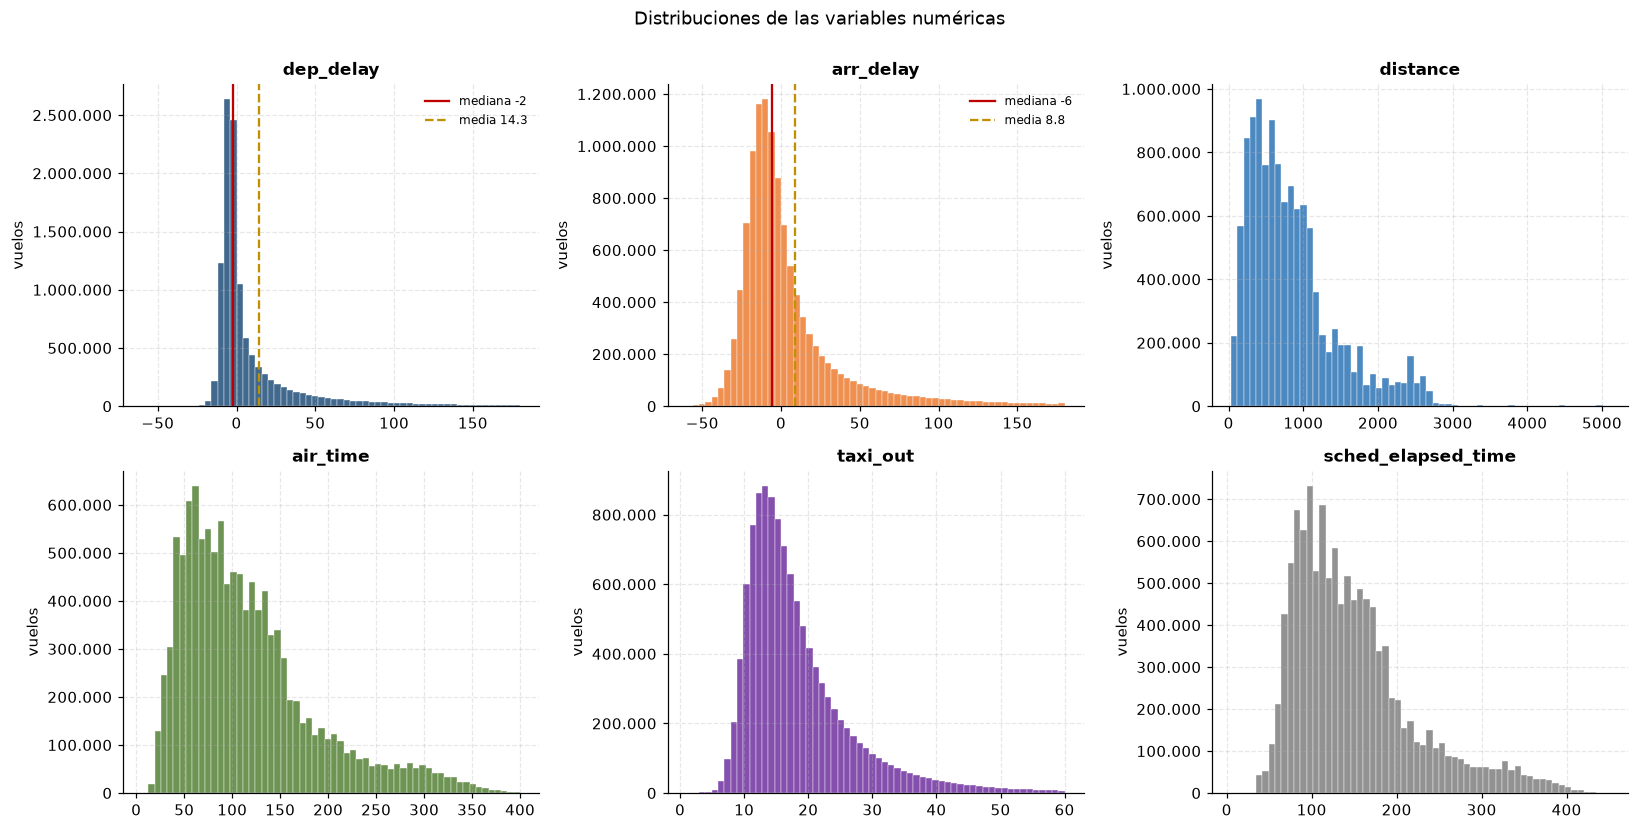

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(15, 7.5))
cfg = [("dep_delay", (-60, 180), AZUL), ("arr_delay", (-60, 180), NARANJA),
       ("distance", None, "#2e75b6"), ("air_time", (0, 400), VERDE),
       ("taxi_out", (0, 60), "#7030a0"), ("sched_elapsed_time", (0, 450), GRIS)]
for e, (col, rango, color) in zip(ax.ravel(), cfg):
    d = df[col].astype("float64").dropna()
    d = d[d.between(*rango)] if rango else d
    e.hist(d, bins=60, color=color, alpha=.85, edgecolor="white", linewidth=.3)
    e.set_title(col); e.set_ylabel("vuelos"); e.yaxis.set_major_formatter(miles)
    if col in ("dep_delay", "arr_delay"):
        e.axvline(df[col].median(), color=ROJO, label=f"mediana {df[col].median():.0f}")
        e.axvline(df[col].mean(), color="#bf9000", ls="--", label=f"media {df[col].mean():.1f}")
        e.legend(fontsize=8)
fig.suptitle("Distribuciones de las variables numéricas", y=1.0)
save(fig, "01_distribuciones.png"); plt.show()

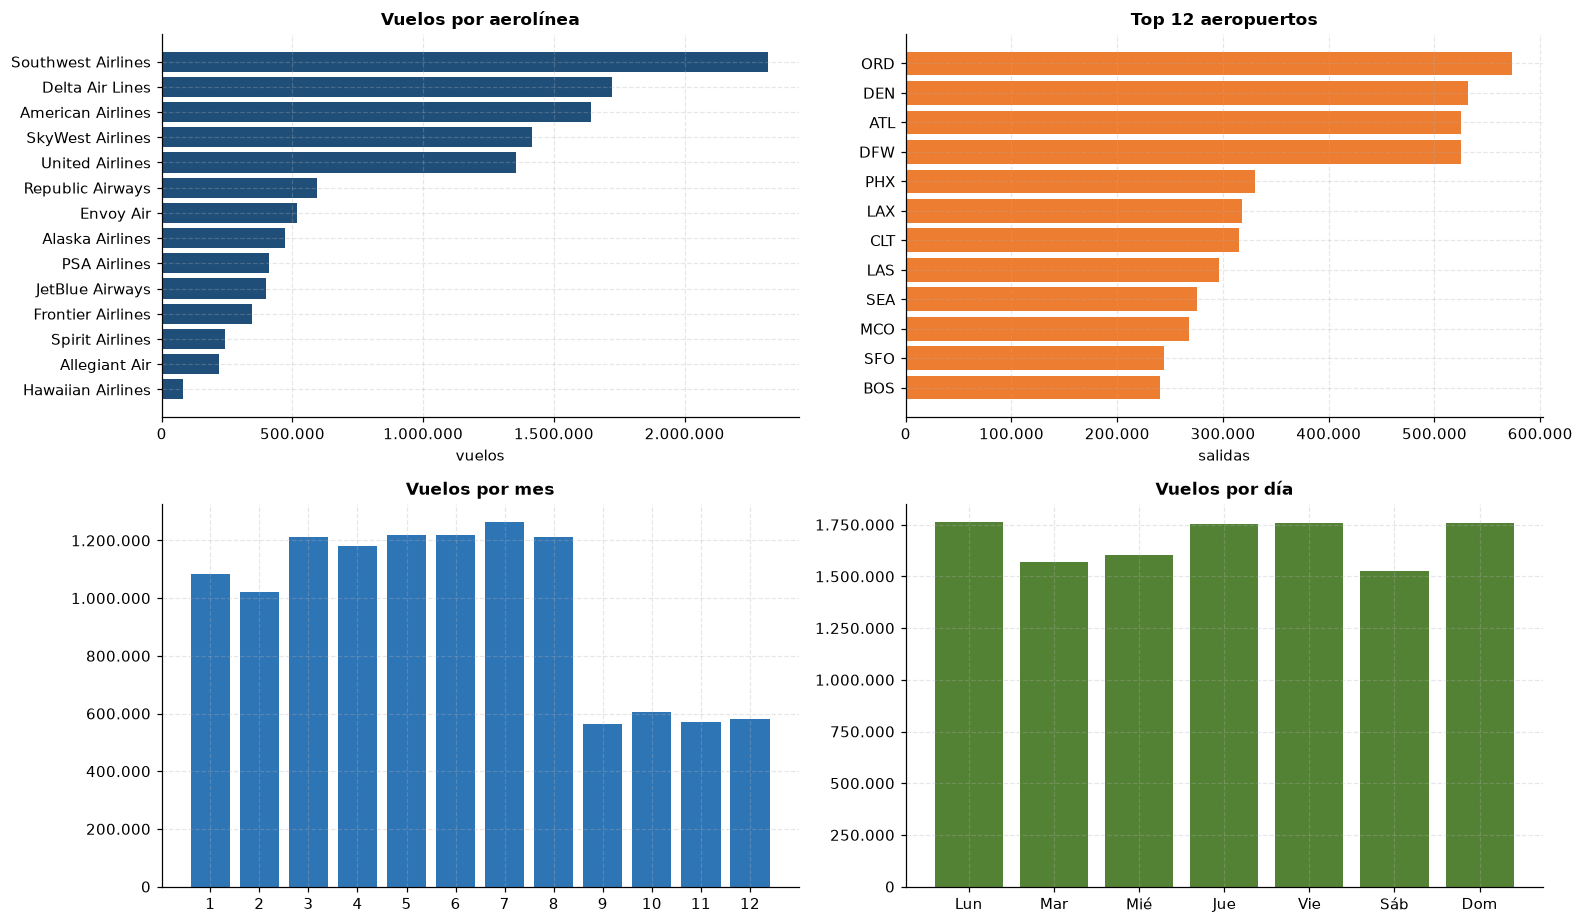

objetivo: 22.81 % retrasados | sin etiqueta: 2.06 %


In [7]:
fig, ax = plt.subplots(2, 2, figsize=(14.5, 8.5))
c = df["airline"].value_counts().sort_values()
ax[0, 0].barh(c.index, c.values, color=AZUL); ax[0, 0].set_title("Vuelos por aerolínea")
ax[0, 0].xaxis.set_major_formatter(miles); ax[0, 0].set_xlabel("vuelos")
c = df["origin"].value_counts().head(12).sort_values()
ax[0, 1].barh(c.index, c.values, color=NARANJA); ax[0, 1].set_title("Top 12 aeropuertos")
ax[0, 1].xaxis.set_major_formatter(miles); ax[0, 1].set_xlabel("salidas")
m = df.groupby("month", observed=True).size()
ax[1, 0].bar(m.index, m.values, color="#2e75b6"); ax[1, 0].set_title("Vuelos por mes")
ax[1, 0].set_xticks(range(1, 13)); ax[1, 0].yaxis.set_major_formatter(miles)
d = df.groupby("day_of_week", observed=True).size()
ax[1, 1].bar(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"], d.values, color=VERDE)
ax[1, 1].set_title("Vuelos por día"); ax[1, 1].yaxis.set_major_formatter(miles)
save(fig, "02_categoricas.png"); plt.show()

obj = df["arr_del15"].dropna()
print(f"objetivo: {obj.mean()*100:.2f} % retrasados | sin etiqueta: {df.arr_del15.isna().mean()*100:.2f} %")

### 3.2 Puntualidad por aerolínea

Brecha de 14,6 min entre la mejor y la peor: las regionales (PSA, Frontier) encabezan el retraso.

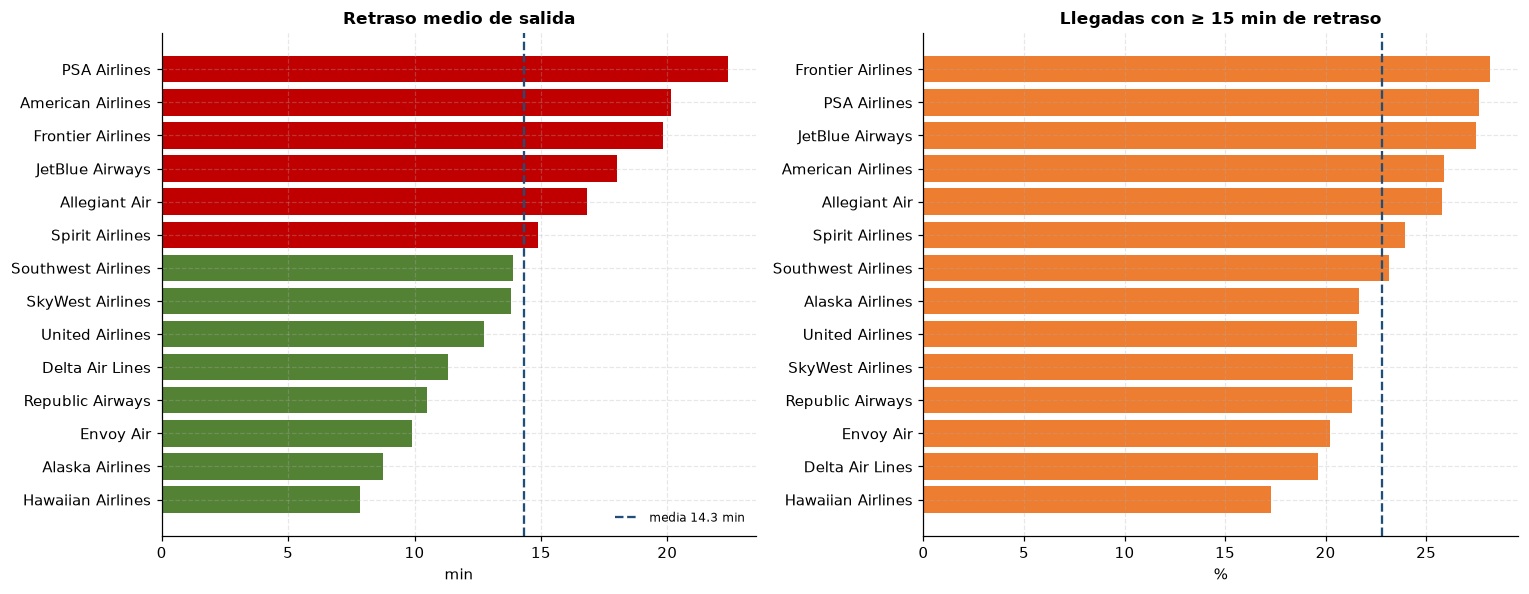

,vuelos,retraso,tarde,cancela
airline,,,,
PSA Airlines,411822,22.40,27.60,5.20
American Airlines,1641071,20.10,25.90,2.10
Frontier Airlines,345485,19.80,28.20,2.00
JetBlue Airways,397034,18.00,27.50,2.80
Allegiant Air,218341,16.80,25.80,0.60
Spirit Airlines,241717,14.90,24.00,2.70
Southwest Airlines,2319717,13.90,23.20,0.90
SkyWest Airlines,1416733,13.80,21.30,1.60
United Airlines,1354575,12.70,21.60,1.00


In [8]:
aer = df.groupby("airline", observed=True).agg(vuelos=("arr_del15", "size"),
        retraso=("dep_delay", "mean"), tarde=("arr_del15", "mean"), cancela=("cancelled", "mean"))
aer[["tarde", "cancela"]] *= 100
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
a = aer.sort_values("retraso")
ax[0].barh(a.index, a["retraso"], color=[ROJO if v > df.dep_delay.mean() else VERDE for v in a["retraso"]])
ax[0].axvline(df.dep_delay.mean(), color=AZUL, ls="--", label=f"media {df.dep_delay.mean():.1f} min")
ax[0].set_title("Retraso medio de salida"); ax[0].set_xlabel("min"); ax[0].legend(fontsize=8)
a = aer.sort_values("tarde")
ax[1].barh(a.index, a["tarde"], color=NARANJA); ax[1].axvline(obj.mean()*100, color=AZUL, ls="--")
ax[1].set_title("Llegadas con ≥ 15 min de retraso"); ax[1].set_xlabel("%")
save(fig, "03_aerolineas.png"); plt.show()
aer.sort_values("retraso", ascending=False).round(1)

### 3.3 Puntualidad por aeropuerto

Los *hubs* concentran el retraso (DFW 19,7 min) y los aeropuertos insulares el mejor registro (LIH 4,8 min).

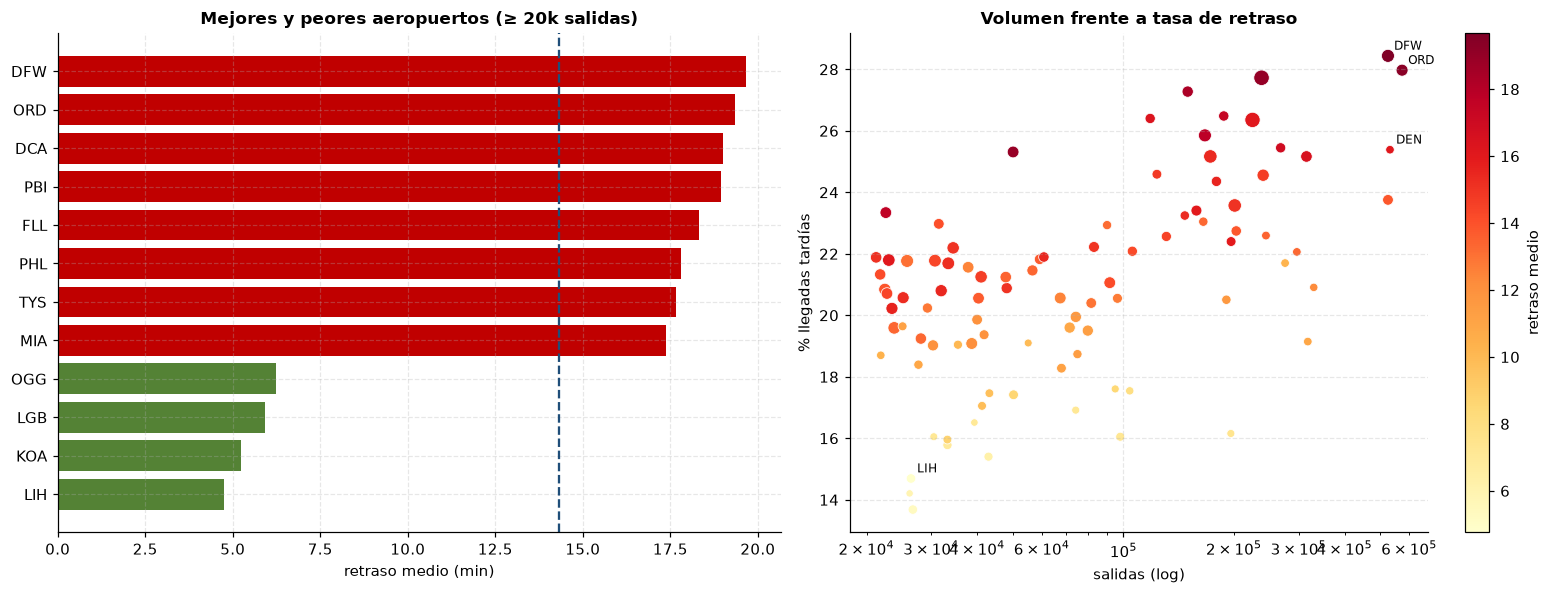

,vuelos,retraso,tarde,cancela
origin,,,,
LIH,26432,4.76,14.69,1.20
KOA,26736,5.25,13.68,1.17
LGB,26200,5.92,14.21,0.42
OGG,42955,6.22,15.40,1.01
MIA,187640,17.39,26.48,1.54
TYS,22572,17.66,23.34,2.19
PHL,166730,17.81,25.85,2.86
FLL,149669,18.32,27.27,1.97
PBI,50119,18.94,25.31,2.20


In [9]:
aero = df.groupby("origin", observed=True).agg(vuelos=("arr_del15", "size"),
        retraso=("dep_delay", "mean"), tarde=("arr_del15", "mean"), cancela=("cancelled", "mean"))
aero[["tarde", "cancela"]] *= 100
grandes = aero[aero["vuelos"] >= 20_000]
ext = pd.concat([grandes.nlargest(8, "retraso"), grandes.nsmallest(4, "retraso")]).sort_values("retraso")
fig, ax = plt.subplots(1, 2, figsize=(14.5, 5.5))
ax[0].barh(ext.index, ext["retraso"],
           color=[ROJO if v > df.dep_delay.mean() else VERDE for v in ext["retraso"]])
ax[0].axvline(df.dep_delay.mean(), color=AZUL, ls="--"); ax[0].set_title("Mejores y peores aeropuertos (≥ 20k salidas)")
ax[0].set_xlabel("retraso medio (min)")
s = ax[1].scatter(grandes["vuelos"], grandes["tarde"], s=grandes["cancela"]*20+15,
                  c=grandes["retraso"], cmap="YlOrRd", edgecolor="white", linewidth=.5)
ax[1].set_xscale("log"); ax[1].set_title("Volumen frente a tasa de retraso")
ax[1].set_xlabel("salidas (log)"); ax[1].set_ylabel("% llegadas tardías")
for code in ["DFW", "ORD", "LIH", "DEN"]:
    ax[1].annotate(code, (grandes.loc[code, "vuelos"], grandes.loc[code, "tarde"]), fontsize=8,
                   xytext=(4, 4), textcoords="offset points")
plt.colorbar(s, ax=ax[1], label="retraso medio")
save(fig, "04_aeropuertos.png"); plt.show()
ext[["vuelos", "retraso", "tarde", "cancela"]].round(2)

### 3.4 Hora del día y día de la semana

El retraso se **acumula** con las rotaciones: 4,1 min a las 06:00 frente a 24,3 min a las 19:00 (factor 6).

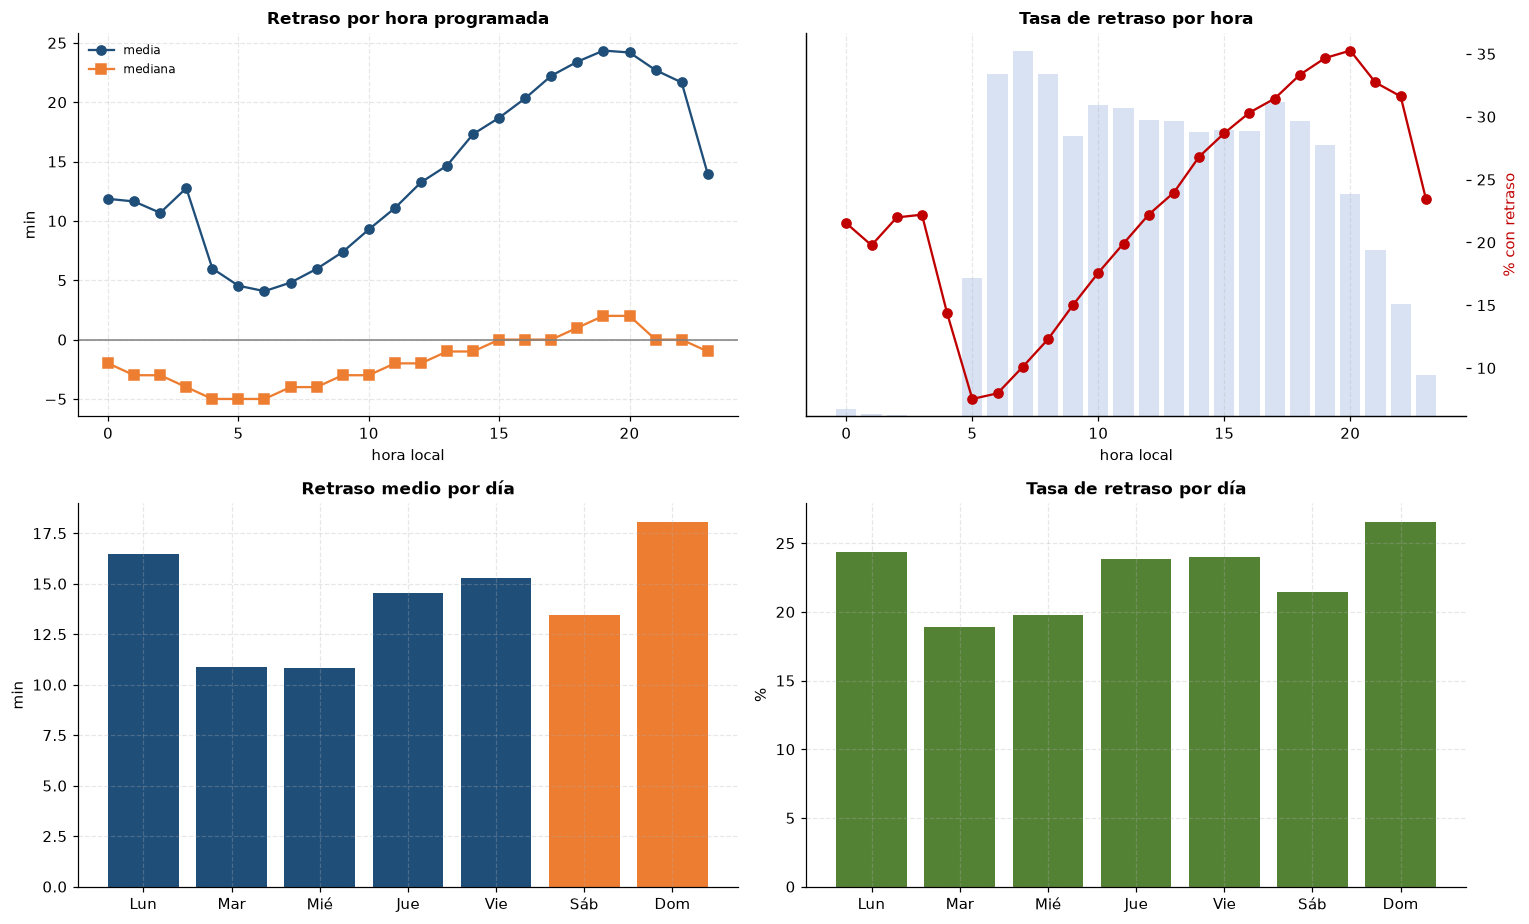

mejor hora 06:00 (4.1 min) | peor 19:00 (24.3 min)


In [10]:
h = df.groupby("hora", observed=True).agg(vuelos=("dep_delay", "size"), media=("dep_delay", "mean"),
                                          mediana=("dep_delay", "median"), tarde=("dep_del15", "mean"))
h["tarde"] *= 100
d = df.groupby("day_of_week", observed=True).agg(media=("dep_delay", "mean"), tarde=("arr_del15", "mean"))
d["tarde"] *= 100
fig, ax = plt.subplots(2, 2, figsize=(14, 8.5))
ax[0, 0].plot(h.index, h["media"], "o-", color=AZUL, label="media")
ax[0, 0].plot(h.index, h["mediana"], "s-", color=NARANJA, label="mediana")
ax[0, 0].axhline(0, color=GRIS, lw=1); ax[0, 0].legend(fontsize=8)
ax[0, 0].set_title("Retraso por hora programada"); ax[0, 0].set_xlabel("hora local"); ax[0, 0].set_ylabel("min")
ax[0, 1].bar(h.index, h["vuelos"], color="#d9e2f3", width=.8)
ax2 = ax[0, 1].twinx(); ax2.plot(h.index, h["tarde"], "o-", color=ROJO); ax2.grid(False)
ax2.set_ylabel("% con retraso", color=ROJO)
ax[0, 1].set_xlabel("hora local"); ax[0, 1].set_yticks([]); ax[0, 1].set_title("Tasa de retraso por hora")
ax[1, 0].bar(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"], d["media"],
             color=[NARANJA if i > 4 else AZUL for i in range(7)])
ax[1, 0].set_title("Retraso medio por día"); ax[1, 0].set_ylabel("min")
ax[1, 1].bar(["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"], d["tarde"], color=VERDE)
ax[1, 1].set_title("Tasa de retraso por día"); ax[1, 1].set_ylabel("%")
save(fig, "05_horario.png"); plt.show()
print(f"mejor hora {h['media'].idxmin():02d}:00 ({h['media'].min():.1f} min) | "
      f"peor {h['media'].idxmax():02d}:00 ({h['media'].max():.1f} min)")

### 3.5 Serie diaria y estacionalidad

Julio (21,5 min) y diciembre (18,3 min) son los peores meses; septiembre (8,1 min) el mejor. El patrón horario se mantiene en los 12 meses: la estacionalidad **desplaza** la curva, no la cambia de forma.

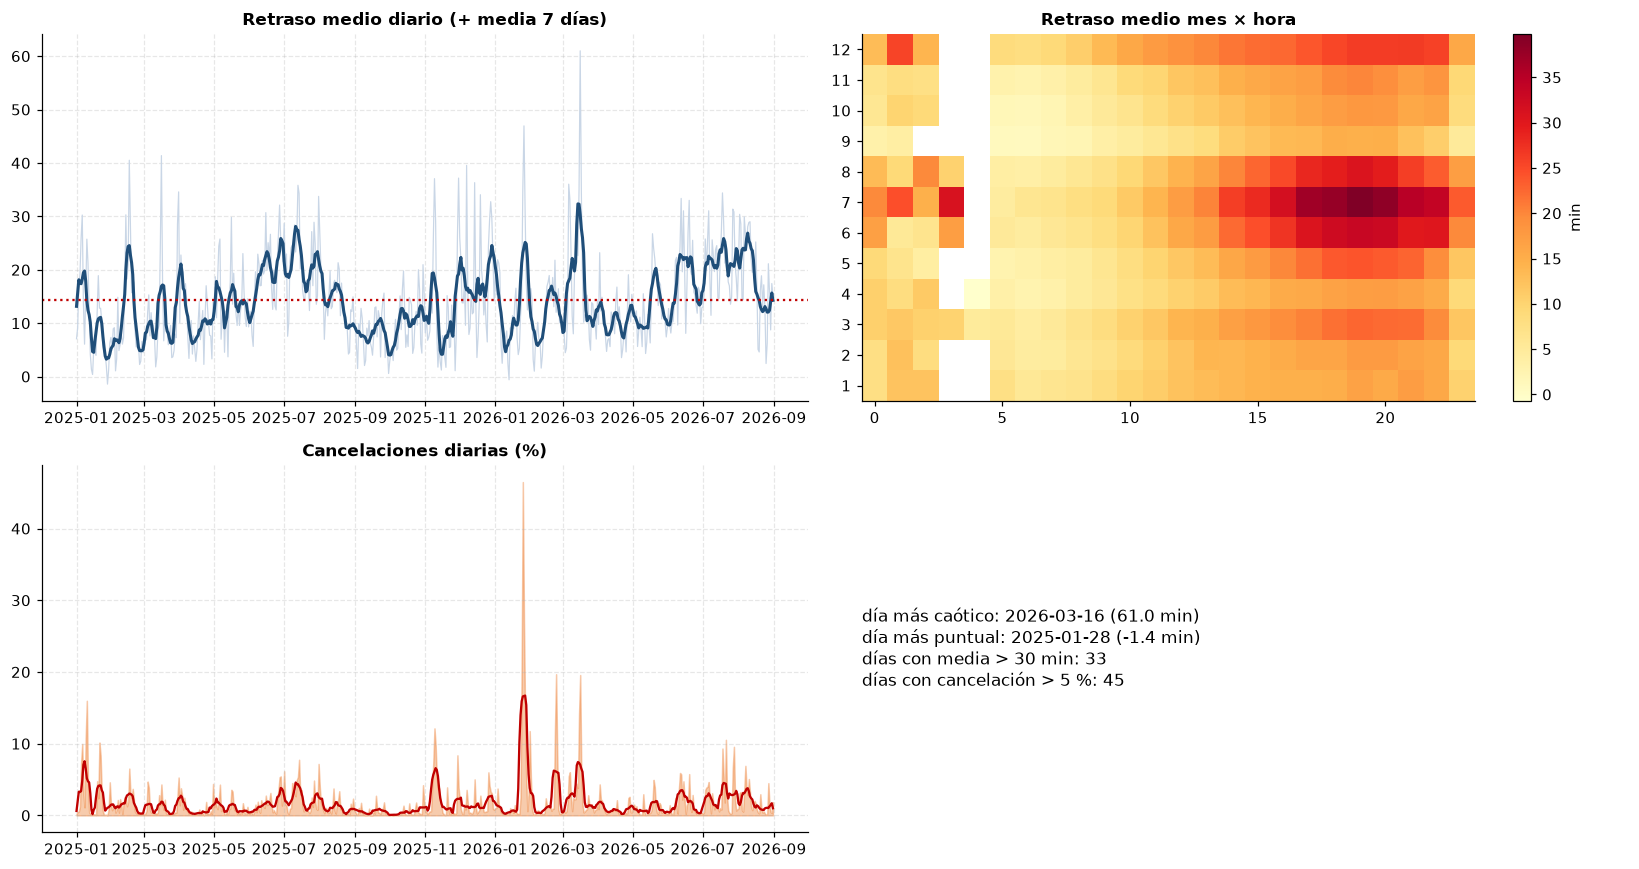

In [11]:
dia = df.groupby("fecha", observed=True).agg(media=("dep_delay", "mean"), cancela=("cancelled", "mean"))
mes_hora = df.pivot_table(index="month", columns="hora", values="dep_delay",
                          aggfunc="mean", observed=True).astype("float64")
n_mes_hora = df.pivot_table(index="month", columns="hora", values="dep_delay", aggfunc="size")
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
ax[0, 0].plot(dia.index, dia["media"], color="#c9d6e6", lw=.8)
ax[0, 0].plot(dia.index, dia["media"].rolling(7, center=True, min_periods=4).mean(), color=AZUL, lw=2)
ax[0, 0].axhline(df.dep_delay.mean(), color=ROJO, ls=":"); ax[0, 0].set_title("Retraso medio diario (+ media 7 días)")
ax[1, 0].fill_between(dia.index, 0, dia["cancela"]*100, color=NARANJA, alpha=.4)
ax[1, 0].plot(dia.index, (dia["cancela"]*100).rolling(7, center=True, min_periods=4).mean(), color=ROJO)
ax[1, 0].set_title("Cancelaciones diarias (%)")
im = ax[0, 1].imshow(mes_hora.where(n_mes_hora >= 100), aspect="auto", cmap="YlOrRd", origin="lower")
ax[0, 1].set_title("Retraso medio mes × hora"); ax[0, 1].set_yticks(range(12), range(1, 13))
ax[0, 1].grid(False); plt.colorbar(im, ax=ax[0, 1], label="min")
ax[1, 1].axis("off")
ax[1, 1].text(0, .5, f"día más caótico: {dia['media'].idxmax():%Y-%m-%d} ({dia['media'].max():.1f} min)\n"
                      f"día más puntual: {dia['media'].idxmin():%Y-%m-%d} ({dia['media'].min():.1f} min)\n"
                      f"días con media > 30 min: {(dia['media'] > 30).sum()}\n"
                      f"días con cancelación > 5 %: {(dia['cancela'] > .05).sum()}",
             fontsize=11, va="center")
save(fig, "06_temporal.png"); plt.show()

### 3.6 Rutas y distancia

Distancia y duración son redundantes (r = 0,984) y el retraso es plano entre tramos: la distancia no explica el retraso. La red está fragmentada en 7 344 rutas.

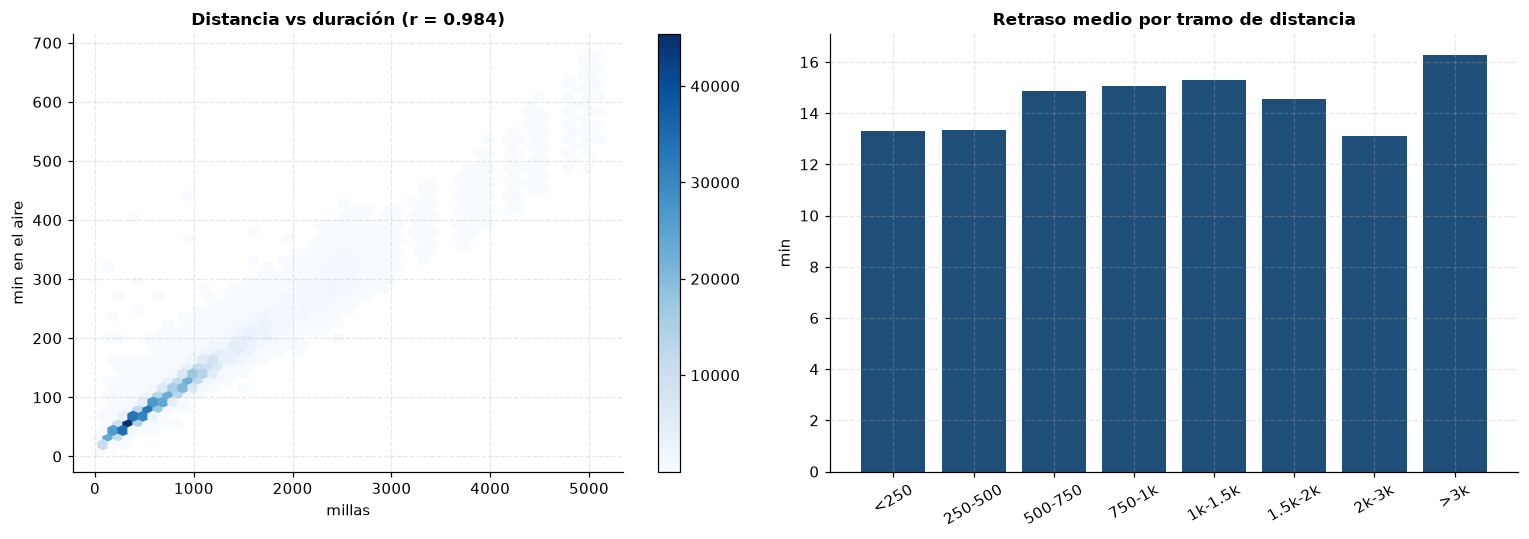

top 50 rutas = 5.8 % del volumen


,,vuelos,retraso,tarde
origin,dest,,,
LGA,ORD,19292,21.00,30.60
ORD,LGA,19292,22.60,30.70
LAX,SFO,18626,13.60,33.20
SFO,LAX,18626,12.90,25.40
OGG,HNL,17267,3.30,13.70
HNL,OGG,17262,3.50,13.30
LAX,JFK,17046,17.60,21.20
JFK,LAX,17043,13.60,22.30


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
hb = ax[0].hexbin(muestra["distance"], muestra["air_time"], gridsize=50, cmap="Blues", mincnt=1)
ax[0].set_title(f"Distancia vs duración (r = {muestra[['distance','air_time']].corr().iloc[0,1]:.3f})")
ax[0].set_xlabel("millas"); ax[0].set_ylabel("min en el aire"); plt.colorbar(hb, ax=ax[0])
cortes = [0, 250, 500, 750, 1000, 1500, 2000, 3000, 6000]
df["tramo"] = pd.cut(df["distance"], cortes, labels=["<250", "250-500", "500-750", "750-1k",
                                                     "1k-1.5k", "1.5k-2k", "2k-3k", ">3k"])
t = df.groupby("tramo", observed=True).dep_delay.mean()
ax[1].bar(t.index.astype(str), t.values, color=AZUL)
ax[1].set_title("Retraso medio por tramo de distancia"); ax[1].set_ylabel("min"); ax[1].tick_params(axis="x", rotation=30)
save(fig, "07_rutas.png"); plt.show()

r = df.groupby(["origin", "dest"], observed=True).agg(vuelos=("dep_delay", "size"),
                                                      retraso=("dep_delay", "mean"),
                                                      tarde=("arr_del15", "mean"))
r["tarde"] *= 100
print(f"top 50 rutas = {r.vuelos.nlargest(50).sum()/r.vuelos.sum()*100:.1f} % del volumen")
r.nlargest(8, "vuelos").round(1)

### 3.7 Causas del retraso

El clima explica el 64 % de las cancelaciones pero sólo el 6,4 % de los minutos: el retraso es un problema **interno** (aeronave precedente 39,5 %, aerolínea 32,6 %).

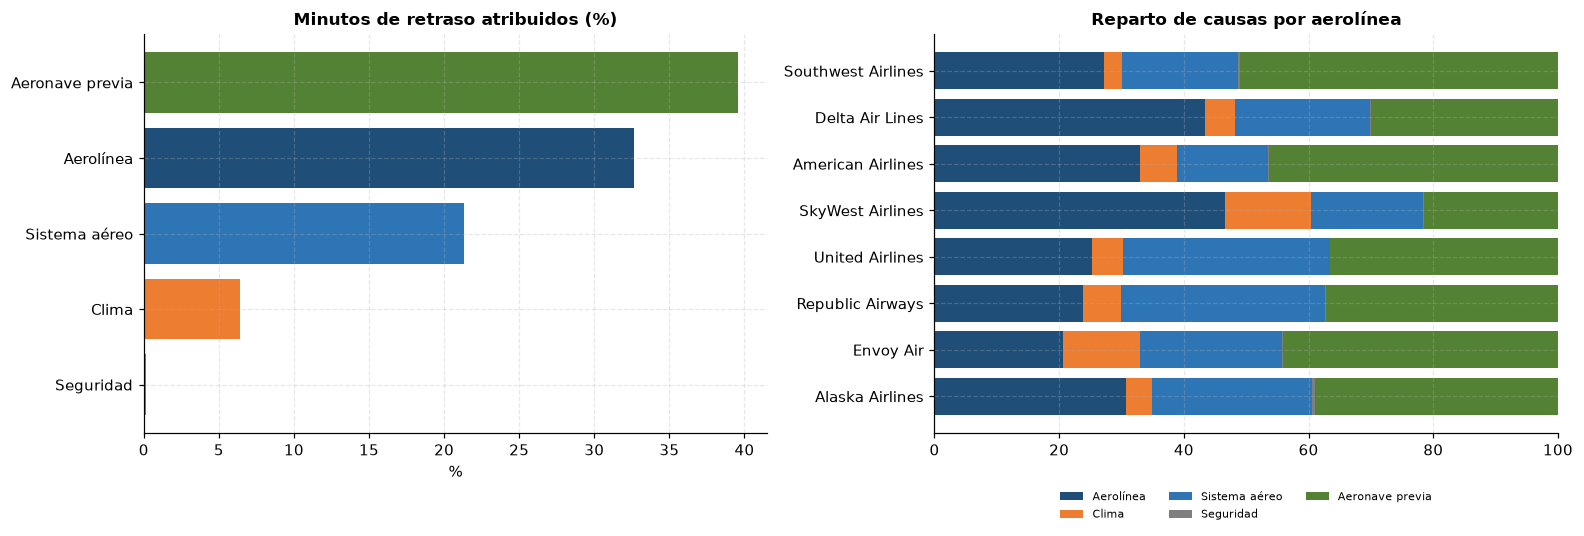

cancellation_reason
Weather               64.30
Carrier               20.80
National Air System   14.90
Security               0.10


In [13]:
CAUSAS = ["carrier_delay", "weather_delay", "nas_delay", "security_delay", "late_aircraft_delay"]
NOMBRES = ["Aerolínea", "Clima", "Sistema aéreo", "Seguridad", "Aeronave previa"]
COL_CAUSA = dict(zip(CAUSAS, [AZUL, NARANJA, "#2e75b6", GRIS, VERDE]))
min_causa = df[CAUSAS].sum(); parte = min_causa/min_causa.sum()*100
fig, ax = plt.subplots(1, 2, figsize=(14.5, 5))
o = parte.sort_values()
ax[0].barh([NOMBRES[CAUSAS.index(c)] for c in o.index], o.values, color=[COL_CAUSA[c] for c in o.index])
ax[0].set_title("Minutos de retraso atribuidos (%)"); ax[0].set_xlabel("%")
top = df["airline"].value_counts().head(8).index
ca = df[df["airline"].isin(top)].groupby("airline", observed=True)[CAUSAS].sum()
rep = (ca.div(ca.sum(axis=1), axis=0)*100).loc[top[::-1]]
izq = np.zeros(len(rep))
for c, nom in zip(CAUSAS, NOMBRES):
    col = COL_CAUSA[c]
    ax[1].barh(rep.index, rep[c], left=izq, color=col, label=nom); izq += rep[c].values
ax[1].set_title("Reparto de causas por aerolínea"); ax[1].set_xlim(0, 100)
ax[1].legend(fontsize=7.5, ncol=3, loc="upper center", bbox_to_anchor=(.5, -.12))
save(fig, "08_causas.png"); plt.show()

print(df["cancellation_reason"].value_counts(normalize=True).mul(100).round(1).to_string())

### 3.8 Correlaciones

Salida y llegada correlacionan 0,969 (Pearson): el retraso se hereda. Por eso `dep_delay` **no puede** usarse como predictora (leakage); en la fase 3 se emulará con el retraso previo de la aeronave.

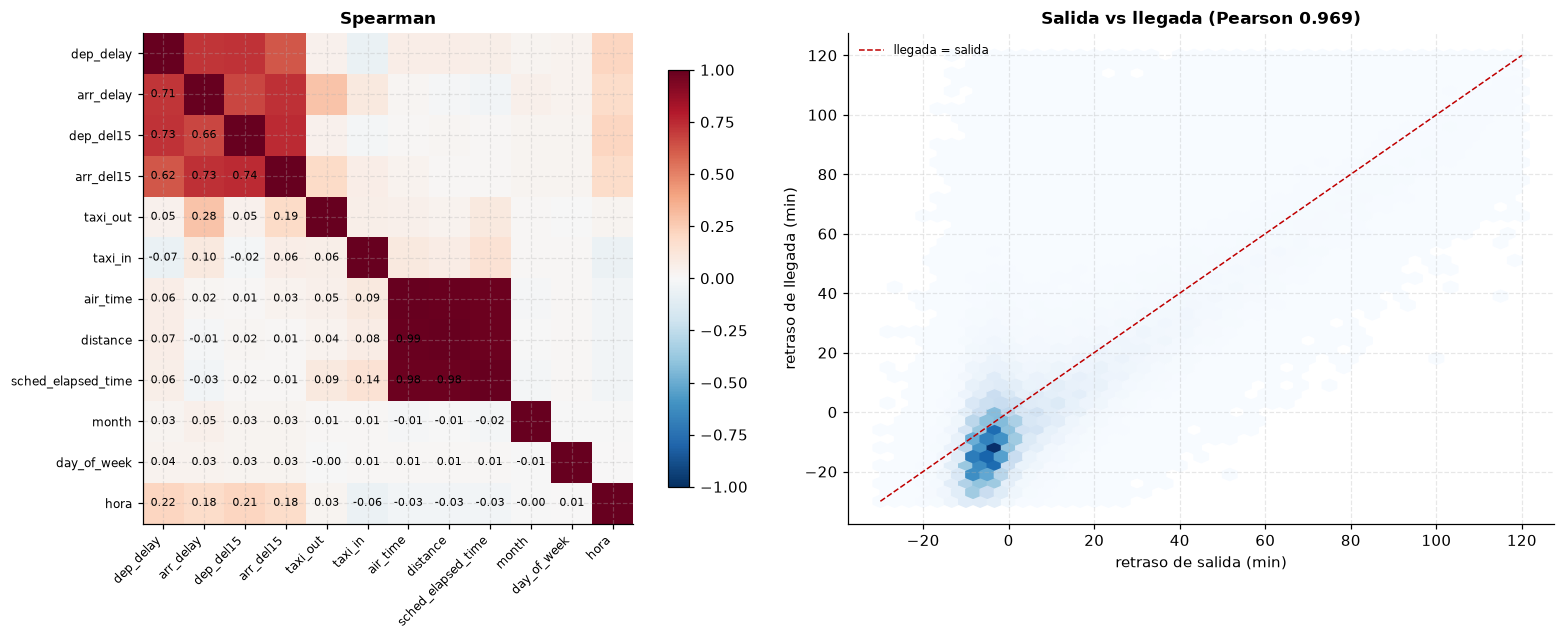

In [14]:
vars_c = ["dep_delay", "arr_delay", "dep_del15", "arr_del15", "taxi_out", "taxi_in",
          "air_time", "distance", "sched_elapsed_time", "month", "day_of_week", "hora"]
sp = muestra[vars_c].astype("float64").corr(method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(15, 5.8))
im = ax[0].imshow(sp, cmap="RdBu_r", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(sp)), sp.columns, rotation=45, ha="right", fontsize=8)
ax[0].set_yticks(range(len(sp)), sp.columns, fontsize=8); ax[0].set_title("Spearman")
for i in range(1, len(sp)):
    for j in range(i):
        ax[0].text(j, i, f"{sp.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, ax=ax[0], shrink=.85)
par = muestra[["dep_delay", "arr_delay"]].dropna().astype("float64")
par = par[par.dep_delay.between(-30, 120) & par.arr_delay.between(-30, 120)]
ax[1].hexbin(par.dep_delay, par.arr_delay, gridsize=45, cmap="Blues", mincnt=1)
ax[1].plot([-30, 120], [-30, 120], color=ROJO, ls="--", lw=1, label="llegada = salida")
ax[1].set_xlabel("retraso de salida (min)"); ax[1].set_ylabel("retraso de llegada (min)")
ax[1].set_title(f"Salida vs llegada (Pearson {muestra[['dep_delay','arr_delay']].corr().iloc[0,1]:.3f})")
ax[1].legend(fontsize=8)
save(fig, "09_correlaciones.png"); plt.show()

### 3.9 Hallazgos del análisis

| # | Hallazgo | Evidencia | Consecuencia |
|---|---|---|---|
| 1 | 22,8 % de vuelos llega tarde | `arr_del15` = 0,228 | Clase positiva suficiente para clasificar |
| 2 | El retraso se acumula en el día | 4,1 → 24,3 min | La hora es la variable clave |
| 3 | Estacionalidad de doble pico | jul 21,5 · sep 8,1 min | Validación temporal obligatoria |
| 4 | Brecha entre aerolíneas | 7,9 vs 22,4 min | `airline` aporta señal |
| 5 | Los *hubs* concentran el retraso | DFW 19,7 · LIH 4,8 min | Añadir congestión del aeropuerto |
| 6 | El retraso se hereda | Pearson 0,969 | Prohibido usar variables post-despegue |
| 7 | El clima no es la causa del retraso | 6,4 % de minutos | Enfocar en rotación y gestión |
| 8 | Domingos y lunes son los peores | 18,1 · 16,5 min | `day_of_week` aporta poco pero positivo |

## 4. Calidad de los datos

Se evalúan siete dimensiones con una regla objetiva y un umbral fijado *a priori*. Un fallo no bloquea el proyecto: se documenta y se corrige en la fase 3.

In [15]:
REG = []
def check(cod, dim, prueba, malos, total, umbral=0.0, sev="Alta", accion="—"):
    tasa = 100*malos/total if total else 0
    REG.append({"codigo": cod, "dimension": dim, "prueba": prueba, "afectados": int(malos),
                "tasa_%": round(tasa, 4), "umbral_%": umbral,
                "estado": "OK" if tasa <= umbral else "REVISAR",
                "severidad": sev, "accion": accion})

cnt = lambda m: int(pd.Series(m).fillna(False).sum())
n = len(df)
print("registro de calidad listo")

registro de calidad listo


### 4.1 Completitud

La ausencia es **estructural**: `arr_delay` falta exactamente cuando el vuelo se cancela o se desvía. Imputar sería inventar el dato.

In [16]:
estado = df.arr_delay.isna().map({False: "con etiqueta", True: "sin etiqueta"})
print(pd.crosstab([df.cancelled, df.diverted], estado, margins=True).to_string())
check("C1", "Completitud", "etiqueta ausente en vuelo operado",
      cnt(df.arr_delay.isna() & (df.cancelled == 0) & (df.diverted == 0)), n, 0.001, "Crítica")
check("C2", "Completitud", "salida ausente en vuelo operado",
      cnt(df.dep_delay.isna() & (df.cancelled == 0)), n, 0.001, "Crítica")
check("C3", "Completitud", "matrícula ausente", cnt(df.tail_number.isna()), n, 0.5, "Media", "categoría DESCONOCIDA")
check("C4", "Completitud", "causa ausente en vuelo retrasado",
      cnt((df.arr_del15 == 1) & df.carrier_delay.isna()), cnt(df.arr_del15 == 1), 0.001)
check("C5", "Completitud", "código de cancelación ausente",
      cnt((df.cancelled == 1) & df.cancellation_code.isna()), cnt(df.cancelled == 1), 0.001)
print(f"columnas con nulos: {int((perfil['nulos'] > 0).sum())} | ninguna inesperada")

arr_delay           con etiqueta  sin etiqueta       All
cancelled diverted                                      
0         0             11488350             1  11488351
          1                    0         35199     35199
1         0                    0        206801    206801
All                     11488350        242001  11730351


columnas con nulos: 19 | ninguna inesperada


### 4.2 Unicidad, validez y consistencia

Las reglas aritméticas internas se cumplen al 99,99 %; los defectos están localizados y son corregibles.

In [17]:
k = ["flight_date", "airline", "flight_number", "origin", "dest"]
check("U1", "Unicidad", "duplicado exacto (muestra)", cnt(muestra.duplicated()), len(muestra), 0, "Crítica")
check("U2", "Unicidad", "vuelo duplicado en la misma fecha", cnt(df.duplicated(subset=k)), n, 0, "Crítica")
horas = sum(cnt((df[c] > 2359) | (df[c] % 100 >= 60)) for c in ["sched_dep_time", "dep_time", "sched_arr_time", "arr_time"])
check("V1", "Validez", "horas 2400 en lugar de 0000", horas, n, 0.02, "Media", "normalizar 2400→0000")
check("V2", "Validez", "retrasos fuera de [-120, 1440]",
      cnt((df.dep_delay < -120) | (df.dep_delay > 1440)), n, 0.02)
check("V3", "Validez", "retrasos de salida > 6 h", cnt(df.dep_delay > 360), n, 0.1, "Media", "acotar a 360 min")
check("V4", "Validez", "duración programada ≤ 0", cnt(df.sched_elapsed_time <= 0), n, 0.001)
check("V5", "Validez", "distancia fuera de (0, 6000]", cnt((df.distance <= 0) | (df.distance > 6000)), n)
check("V6", "Validez", "rodaje > 300 min", cnt((df.taxi_out > 300) | (df.taxi_in > 300)), n, 0.01)
check("V7", "Validez", "flags fuera de {0, 1}", cnt(~df.cancelled.isin([0, 1])) + cnt(~df.diverted.isin([0, 1])), n)
pd.DataFrame(REG).tail(10)[["codigo", "prueba", "afectados", "tasa_%", "estado"]]

,codigo,prueba,afectados,tasa_%,estado
4,C5,código de cancelación ausente,0,0.00,OK
5,U1,duplicado exacto (muestra),0,0.00,OK
6,U2,vuelo duplicado en la misma fecha,0,0.00,OK
7,V1,horas 2400 en lugar de 0000,7579,0.06,REVISAR
8,V2,"retrasos fuera de [-120, 1440]",1167,0.01,OK
9,V3,retrasos de salida > 6 h,44094,0.38,REVISAR
10,V4,duración programada ≤ 0,14,0.00,OK
11,V5,"distancia fuera de (0, 6000]",0,0.00,OK
12,V6,rodaje > 300 min,15,0.00,OK
13,V7,"flags fuera de {0, 1}",0,0.00,OK


In [18]:
def mins(s):
    s = s.astype("Float64"); return (s//100)*60 + s % 100

check("S1", "Consistencia", "dep_del15 ≠ (dep_delay ≥ 15)",
      cnt((df.dep_delay >= 15).astype("Int8") != df.dep_del15), cnt(df.dep_delay.notna()), 0, "Crítica")
check("S2", "Consistencia", "arr_del15 ≠ (arr_delay ≥ 15)",
      cnt((df.arr_delay >= 15).astype("Int8") != df.arr_del15), cnt(df.arr_delay.notna()), 0, "Crítica")
dif = (mins(df.dep_time) - mins(df.sched_dep_time) - df.dep_delay) % 1440
check("S3", "Consistencia", "dep_time ≠ sched_dep_time + dep_delay",
      cnt(dif.where(dif <= 720, dif - 1440).abs() > 2), cnt(df.dep_delay.notna()), 0.01)
check("S4", "Consistencia", "duración ≠ vuelo + rodajes",
      cnt((df.actual_elapsed_time - df.air_time - df.taxi_out - df.taxi_in).abs() > 0),
      cnt(df.actual_elapsed_time.notna()), 0)
ok = df[CAUSAS].notna().all(axis=1)
check("S5", "Consistencia", "suma de causas ≠ arr_delay",
      cnt((df.loc[ok, CAUSAS].sum(axis=1) - df.loc[ok, "arr_delay"]).abs() > 0), int(ok.sum()), 0.01)
check("S6", "Consistencia", "cancelado con hora de salida", cnt((df.cancelled == 1) & df.dep_delay.notna()),
      cnt(df.cancelled == 1), 0.5, "Alta", "excluir del entrenamiento")
pd.DataFrame(REG).tail(6)[["codigo", "prueba", "afectados", "tasa_%", "estado"]]

,codigo,prueba,afectados,tasa_%,estado
14,S1,dep_del15 ≠ (dep_delay ≥ 15),0,0.00,OK
15,S2,arr_del15 ≠ (arr_delay ≥ 15),0,0.00,OK
16,S3,dep_time ≠ sched_dep_time + dep_delay,69,0.00,OK
17,S4,duración ≠ vuelo + rodajes,0,0.00,OK
18,S5,suma de causas ≠ arr_delay,147,0.01,OK
19,S6,cancelado con hora de salida,8243,3.99,REVISAR


### 4.3 Integridad referencial y exactitud

Los 361 aeropuertos y las 14 aerolíneas existen en sus catálogos, y el agregado diario **coincide exactamente** con los hechos: 202 872 combinaciones aeropuerto-día.

In [19]:
ap = pd.read_csv(RAW/"airports.csv", dtype={"iata_code": "string", "state": "string"})
al = pd.read_csv(RAW/"airlines.csv", dtype={"airline_code": "string"})
check("R1", "Integridad", "origen fuera del catálogo", len(set(df.origin) - set(ap.iata_code)), len(set(df.origin)), 0, "Crítica")
check("R2", "Integridad", "destino fuera del catálogo", len(set(df.dest) - set(ap.iata_code)), len(set(df.dest)), 0, "Crítica")
check("R3", "Integridad", "aerolínea fuera del catálogo",
      len(set(df.airline) - set(al.airline)), df.airline.nunique(), 0, "Crítica")

est = pd.read_csv(RAW/"daily_airport_stats.csv", parse_dates=["flight_date"], dtype={"airport": "string"})
prop = df.groupby(["fecha", "origin"], observed=True).agg(vuelos=("cancelled", "size"),
        cancelados=("cancelled", "sum"), desviados=("diverted", "sum"), retraso=("dep_delay", "mean")).reset_index()
cmp = est.merge(prop, left_on=["flight_date", "airport"], right_on=["fecha", "origin"], how="outer", indicator=True)
both = cmp[cmp._merge == "both"]
check("E1", "Exactitud", "vuelos programados distintos del agregado",
      cnt(both.departures_scheduled != both.vuelos) + cnt(cmp._merge != "both"), len(cmp))
check("E2", "Exactitud", "cancelados distintos del agregado", cnt(both.cancelled != both.cancelados), len(both))
check("E3", "Exactitud", "desviados distintos del agregado", cnt(both.diverted != both.desviados), len(both))
check("E4", "Exactitud", "retraso medio distinto (> 1 min)",
      cnt((both.dep_delay_mean - both.retraso).abs() > 1), len(both))
print(f"filas comparadas: {len(cmp):,} | solo en una fuente: {cnt(cmp._merge != 'both')}")

filas comparadas: 202,872 | solo en una fuente: 0


### 4.4 Atípicos

Los extremos son reales en su mayoría, pero por encima de 6 h son implausibles: se acotarán sin eliminar filas, porque `arr_del15` no cambia.

Tukey: [-31.5, 36.5] min | fuera del rango: 13.0 %


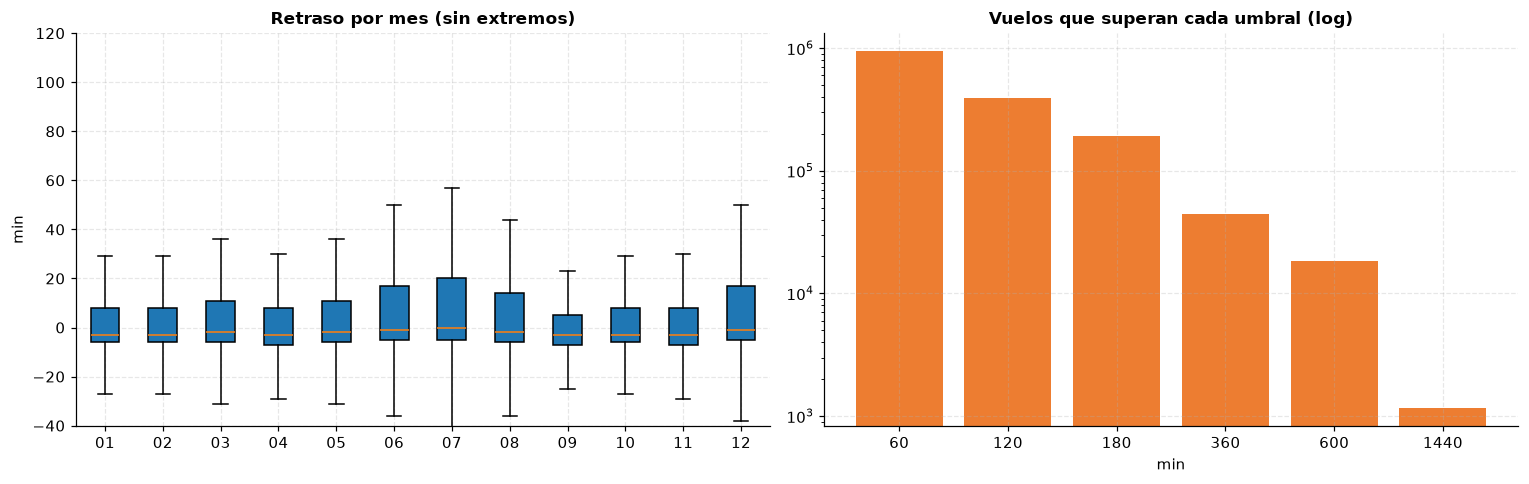

,umbral (min),vuelos,%
0,60,946928,8.21
1,120,389847,3.38
2,180,191900,1.66
3,360,44094,0.38
4,600,18461,0.16
5,1440,1167,0.01


In [20]:
s = df.dep_delay.dropna().astype("float64")
q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
print(f"Tukey: [{q1-1.5*iqr:.1f}, {q3+1.5*iqr:.1f}] min | fuera del rango: "
      f"{cnt((s < q1-1.5*iqr) | (s > q3+1.5*iqr))/len(s)*100:.1f} %")
umbrales = [60, 120, 180, 360, 600, 1440]
tab = pd.DataFrame({"umbral (min)": umbrales,
                    "vuelos": [cnt(s > u) for u in umbrales],
                    "%": [round(cnt(s > u)/len(s)*100, 3) for u in umbrales]})
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].boxplot([df.loc[df.month == m, "dep_delay"].dropna().astype("float64") for m in range(1, 13)],
              tick_labels=[f"{m:02d}" for m in range(1, 13)], showfliers=False, patch_artist=True)
ax[0].set_title("Retraso por mes (sin extremos)"); ax[0].set_ylabel("min"); ax[0].set_ylim(-40, 120)
ax[1].bar(tab["umbral (min)"].astype(str), tab["vuelos"], color=NARANJA); ax[1].set_yscale("log")
ax[1].set_title("Vuelos que superan cada umbral (log)"); ax[1].set_xlabel("min")
save(fig, "10_atipicos.png"); plt.show()
tab

### 4.5 Tablero de calidad

24 de 27 pruebas OK (88.9 %)


,pruebas,ok,cumple_%
dimension,,,
Completitud,5,5,100.00
Consistencia,6,5,83.00
Exactitud,4,4,100.00
Integridad,3,3,100.00
Unicidad,2,2,100.00
Validez,7,5,71.00


,codigo,dimension,prueba,afectados,tasa_%,accion
7,V1,Validez,horas 2400 en lugar de 0000,7579,0.06,normalizar 2400→0000
9,V3,Validez,retrasos de salida > 6 h,44094,0.38,acotar a 360 min
19,S6,Consistencia,cancelado con hora de salida,8243,3.99,excluir del entrenamiento


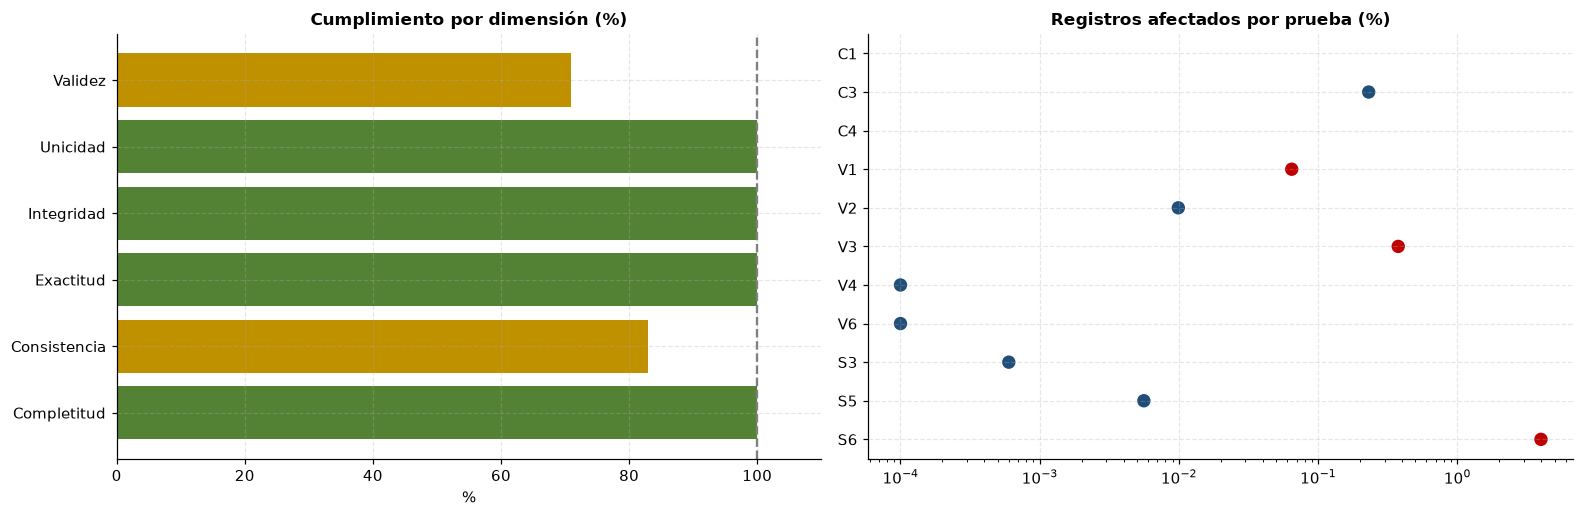

In [21]:
cal = pd.DataFrame(REG)
por_dim = cal.groupby("dimension").agg(pruebas=("codigo", "size"),
                                       ok=("estado", lambda s: int((s == "OK").sum())))
por_dim["cumple_%"] = (por_dim["ok"]/por_dim["pruebas"]*100).round(0)
print(f"{int((cal.estado == 'OK').sum())} de {len(cal)} pruebas OK "
      f"({(cal.estado == 'OK').mean()*100:.1f} %)")
display(por_dim, cal[cal.estado == "REVISAR"][["codigo", "dimension", "prueba", "afectados", "tasa_%", "accion"]])

fig, ax = plt.subplots(1, 2, figsize=(14.5, 4.8))
ax[0].barh(por_dim.index, por_dim["cumple_%"],
           color=[VERDE if v == 100 else "#bf9000" for v in por_dim["cumple_%"]])
ax[0].axvline(100, color=GRIS, ls="--"); ax[0].set_xlim(0, 110)
ax[0].set_title("Cumplimiento por dimensión (%)"); ax[0].set_xlabel("%")
mal = cal[cal.afectados > 0]
ax[1].scatter(mal["tasa_%"], mal["codigo"], c=[ROJO if e == "REVISAR" else AZUL for e in mal.estado], s=60)
ax[1].set_xscale("log"); ax[1].set_title("Registros afectados por prueba (%)"); ax[1].invert_yaxis()
save(fig, "11_tablero.png"); plt.show()

cal.to_csv(TAB/"02_tablero_calidad.csv", index=False, sep=";", decimal=",", encoding="utf-8-sig")

## 5. Decisiones para la fase 3

| # | Decisión | Motivo |
|---|---|---|
| D1 | Objetivo `arr_del15` | Estándar DOT; 22,8 % de positivos |
| D2 | Excluir cancelados y desviados | Sin etiqueta; imputar sería inventar (MNAR) |
| D3 | Excluir variables post-despegue | `dep_delay`, `taxi_out`, `arr_time`, causas → leakage |
| D4 | Acotar continuas a p1–p99 y retrasos a 360 min | 44 094 casos con retrasos implausibles |
| D5 | Normalizar `2400 → 0000` | 7 579 horas fuera de formato |
| D6 | Retraso previo de la misma matrícula | Sustituye a `dep_delay` sin fuga (39,5 % de los minutos) |
| D7 | Congestión por aeropuerto y franja | Los hubs concentran el retraso |
| D8 | Validación temporal (2025 train / 2026 test) | Hay estacionalidad y deriva |
| D9 | Métricas AUC, F1 y recall | La exactitud premia al modelo trivial |

## 6. Conclusiones

- Datos **limpios y coherentes**: integridad referencial y exactitud perfectas, sin duplicados; sólo 3 incidencias acotadas.
- El retraso es **estructural**: hora del día, estación, aeropuerto y aerolínea explican la mayor parte de la variabilidad.
- La causa dominante es **interna** (aeronave previa + aerolínea + NAS ≈ 93 % de los minutos), no meteorológica.
- El riesgo de **fuga de información** es alto (r = 0,97): la fase 3 debe construir variables previas al despegue.
- El plan de la fase 3 ya está definido (D1–D9) y es ejecutable.

In [22]:
print(f"vuelos: {len(df):,} | aerolíneas: {df.airline.nunique()} | aeropuertos: {df.origin.nunique()} "
      f"| rutas: {df.groupby(['origin','dest'], observed=True).ngroups:,}")
print(f"llegada tardía: {df.arr_del15.mean()*100:.2f} % | cancelación: {df.cancelled.mean()*100:.2f} %")
print(f"calidad: {int((cal.estado == 'OK').sum())}/{len(cal)} pruebas OK")
print("artefactos:", len(list(FIG.glob('*.png'))), "figuras |", len(list(TAB.glob('*.csv'))), "tablas")

vuelos: 11,730,351 | aerolíneas: 14 | aeropuertos: 361 | rutas: 7,344
llegada tardía: 22.81 % | cancelación: 1.76 %
calidad: 24/27 pruebas OK
artefactos: 11 figuras | 2 tablas
